In [1]:
import pandas as pd
import xgboost as xgb
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from forecast_checks import ForecastValidator, MakeTrainingData, DELAY_DAYS

In [2]:
trainer = MakeTrainingData()
data = trainer.get_train_test()
train_split = data["train"]
test_split=data["test"]
X_train, y_train = train_split["feature"], train_split["target"]
X_test, y_test = test_split["feature"], test_split["target"]

In [3]:
#Score every model on the same hours: drop test rows where the baseline has no value
scored = X_test["consumption_7days_ago"].notna()
X_test, y_test = X_test[scored], y_test[scored]

In [4]:
#Hyperparameter tuning with CVGrid

NUM_TREES=[100,500,1000]
LEARNING_RATE=[0.025, 0.05, 0.075]
MAX_DEPTH=[5,10,15]

BASE_PARAMS = dict(enable_categorical=True, tree_method="hist", random_state=42)
param_grid = {"n_estimators": NUM_TREES, "learning_rate": LEARNING_RATE, "max_depth": MAX_DEPTH}
#Rows are sorted by time; the gap leaves out ~6 days of rows between fit and validation, like the consumption delay
cv = TimeSeriesSplit(n_splits=3, gap=(DELAY_DAYS + 1) * 24 * X_train["location"].nunique())
search = GridSearchCV(xgb.XGBRegressor(**BASE_PARAMS), param_grid, cv=cv,
                      scoring="neg_mean_absolute_error", refit=False,
                      verbose=True)
search.fit(X_train, y_train)
print("Best params:", search.best_params_)

Fitting 3 folds for each of 27 candidates, totalling 81 fits
Best params: {'learning_rate': 0.05, 'max_depth': 10, 'n_estimators': 1000}


In [5]:
#TRAIN

model = xgb.XGBRegressor(**BASE_PARAMS, **search.best_params_)
model.fit(X_train, y_train)
pred = model.predict(X_test)

In [6]:
#TEST

forecastValidator = (ForecastValidator(y_test, groups=X_test["location"])
                     .add("Same hour last week", X_test["consumption_7days_ago"])
                     .add("XGBoost", pred))
forecastValidator.summary()

,mae,mae_pct_of_total,mse
Same hour last week,0.494499,8.980071,0.650888
XGBoost,0.354347,6.434928,0.313287


In [7]:
forecastValidator.per_group()

mae  mae_pct_of_total       mse
model               group                                            
Same hour last week bergen       0.346706         10.764123  0.175679
                    helsingfors  0.136051          2.121455  0.068545
                    oslo         1.302535         10.667216  2.820663
                    stavanger    0.594116         10.509702  0.552666
                    tromsø       0.181296          9.405561  0.051286
                    trondheim    0.406494         11.247826  0.236820
XGBoost             bergen       0.225763          7.009216  0.081841
                    helsingfors  0.150144          2.341205  0.051337
                    oslo         0.913833          7.483915  1.252512
                    stavanger    0.506842          8.965859  0.399778
                    tromsø       0.112407          5.831596  0.019574
                    trondheim    0.217212          6.010331  0.074832

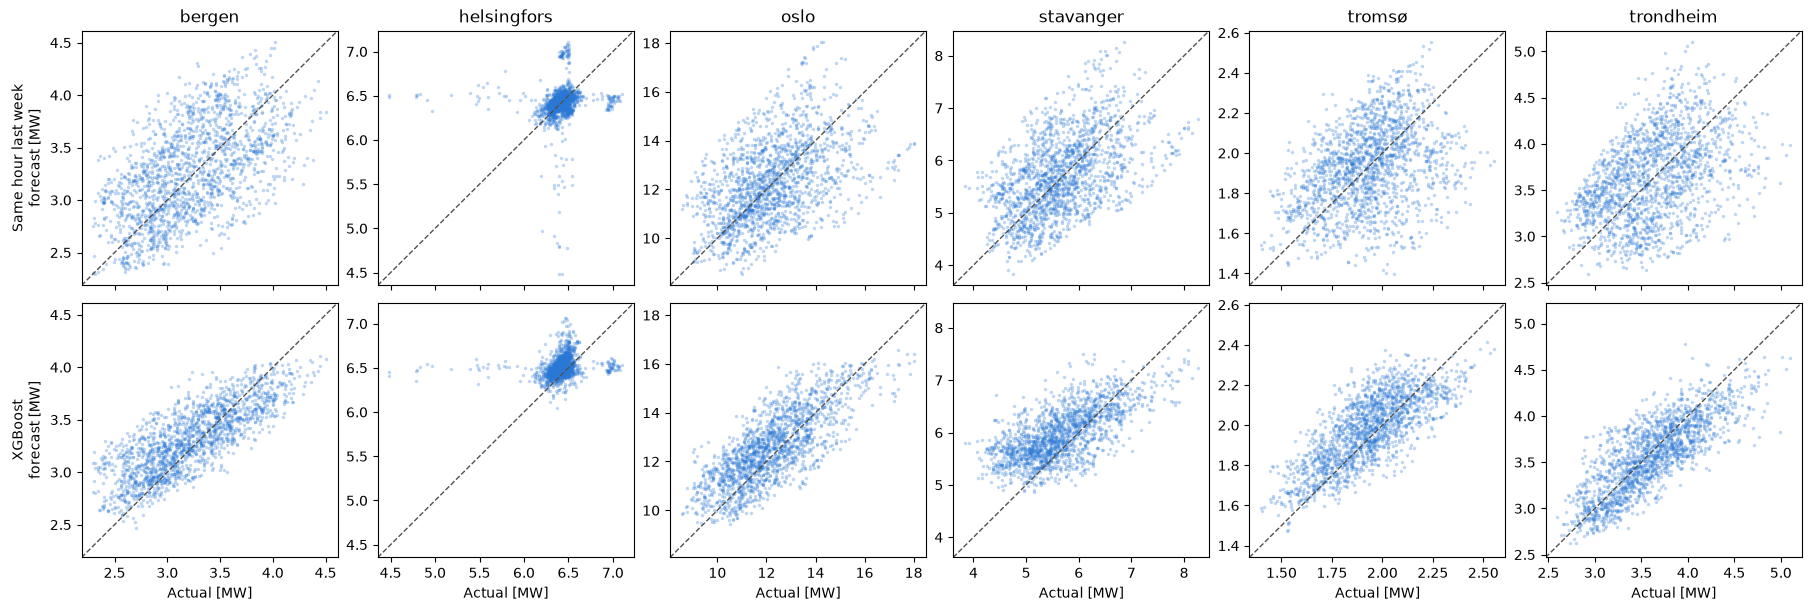

In [8]:
forecastValidator.plot_predicted_vs_actual_consumption()

Er det bedre med jevnere feilfordeling, hvis kostnad ved imbalanse er eksponentiell?